# Ejercicio 4 — Regularización de Tikhonov

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from comun import cargar_datos

datos = cargar_datos()
lam, A, edades, b, b_ideal, x_real = (
    datos[k] for k in ("lam", "A", "edades", "b", "b_ideal", "x_real")
)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

eta = np.linalg.norm(b - b_ideal)
n = A.shape[1]

U, s, Vt = np.linalg.svd(A, full_matrices=False)
beta = U.T @ b


def tikhonov(alpha):
    f = s**2 / (s**2 + alpha**2)          # factores de filtro
    return Vt.T @ (f * beta / s)
def err_rel(x): return np.linalg.norm(x - x_real) / np.linalg.norm(x_real)
def residuo(x): return np.linalg.norm(A @ x - b)

## 1. Qué es la regularización de Tikhonov

La regularización de Tikhonov reemplaza el problema de cuadrados mínimos por

$$x_\alpha = \arg\min_{x}\ \|Ax-b\|_2^2 + \alpha^2\|Lx\|_2^2 ,$$

donde el segundo término **penaliza soluciones "grandes"** (o, con otra $L$, poco suaves). El parámetro $\alpha>0$ regula el compromiso entre ajustar los datos y controlar la solución. En **orden 0** se toma $L=I$ y se penaliza $\|x\|_2$.

Derivando e igualando a cero:

$$(A^\top A + \alpha^2 I)\,x_\alpha = A^\top b .$$

La matriz $A^\top A+\alpha^2I$ es simétrica definida positiva para todo $\alpha>0$, así que la solución existe y es única aunque $A$ esté mal condicionada. Sus autovalores son $\sigma_i^2+\alpha^2$, lo que reduce el número de condición de $\sigma_1^2/\sigma_n^2$ a $(\sigma_1^2+\alpha^2)/(\sigma_n^2+\alpha^2)$. Con la SVD $A=U\Sigma V^\top$,

$$x_\alpha = \sum_{i=1}^{15} f_i\,\frac{u_i^\top b}{\sigma_i}\,v_i, \qquad f_i = \frac{\sigma_i^2}{\sigma_i^2+\alpha^2}\in(0,1).$$

Los **factores de filtro** $f_i$ valen $\approx1$ si $\sigma_i\gg\alpha$ (la componente se conserva) y $\approx\sigma_i^2/\alpha^2$ si $\sigma_i\ll\alpha$ (la componente se atenúa). Es una versión suave de la TSVD del Ej. 3, que usa $f_i\in\{0,1\}$.

**¿Conviene para este problema?** Sí. Los ítems anteriores mostraron que:
- $A$ tiene rango completo pero $\kappa(A)\approx6\times10^3$, con valores singulares chicos;
- en la solución de cuadrados mínimos esos $\sigma_i$ chicos amplifican el ruido (error en $x$ del 17,6 % con un ruido del 0,19 %);
- descartar esas componentes (TSVD) baja el error a ~7 % sin empeorar el residuo.

Tikhonov ataca exactamente esto, y en lugar de un corte abrupto con $k$ entero tiene un parámetro continuo $\alpha$.

## 2. Implementación

Se implementa con la fórmula de filtros sobre la SVD y se verifica contra dos formas equivalentes:

- **Ecuaciones normales regularizadas:** $(A^\top A+\alpha^2I)x = A^\top b$.
- **Sistema aumentado:** $\min_x \left\| \begin{bmatrix}A\\ \alpha I\end{bmatrix}x - \begin{bmatrix}b\\ 0\end{bmatrix}\right\|_2$, que es un problema de cuadrados mínimos común porque su función objetivo es exactamente $\|Ax-b\|^2+\alpha^2\|x\|^2$.

Las tres coinciden ($10^{-10}$ con las ecuaciones normales, que pierden algunos dígitos al formar $A^\top A$, y $10^{-13}$ con el sistema aumentado). Con $\alpha=0$ se recupera la solución de cuadrados mínimos.

In [2]:
alpha_v = 0.3
x_svd = tikhonov(alpha_v)
x_ne = np.linalg.solve(A.T @ A + alpha_v**2 * np.eye(n), A.T @ b)
x_aug = np.linalg.lstsq(
    np.vstack([A, alpha_v * np.eye(n)]),
    np.concatenate([b, np.zeros(n)]),
    rcond=None,
)[0]

print("α = 0.3, ecuaciones normales vs. SVD: ||x_NE - x_SVD|| / ||x_SVD|| =",
      np.linalg.norm(x_ne - x_svd) / np.linalg.norm(x_svd))
print("α = 0.3, sistema aumentado vs. SVD: ||x_aug - x_SVD|| / ||x_SVD|| =",
      np.linalg.norm(x_aug - x_svd) / np.linalg.norm(x_svd))

x_ls_chk = np.linalg.lstsq(A, b, rcond=None)[0]
print("α = 0, tikhonov vs. lstsq: ||x_0 - x_LS|| / ||x_LS|| =",
      np.linalg.norm(tikhonov(0.0) - x_ls_chk) / np.linalg.norm(x_ls_chk))

α = 0.3, ecuaciones normales vs. SVD: ||x_NE - x_SVD|| / ||x_SVD|| = 1.1786127070126267e-10
α = 0.3, sistema aumentado vs. SVD: ||x_aug - x_SVD|| / ||x_SVD|| = 9.321077281868866e-14
α = 0, tikhonov vs. lstsq: ||x_0 - x_LS|| / ||x_LS|| = 1.2514554188923106e-12


## 3. Cómo varía $x_\alpha$ con $\alpha$

- **$\alpha$ muy chico** ($\alpha\lesssim10^{-3}$, muy por debajo de $\sigma_{15}\approx0{,}04$): todos los $f_i\approx1$ y $x_\alpha\approx x_{LS}$, con un error del 17,6 % y las mismas oscilaciones entre edades viejas vecinas.
- **$\alpha$ del orden de los $\sigma_i$ chicos** ($0{,}05\lesssim\alpha\lesssim0{,}5$): se atenúan las componentes con valores singulares chicos, que son las que traen ruido amplificado, empezando por las últimas y llegando a la componente 5 solo hacia el extremo superior del rango. El error baja hasta un **mínimo de ~4 %** cerca de $\alpha\approx0{,}18$, mientras el residuo casi no cambia (≈ $\eta$).
- **$\alpha$ grande** ($\alpha\gtrsim1$): se empiezan a atenuar componentes que sí tienen señal ($\sigma_4\approx3$, $\sigma_3\approx8$). La solución se **sobresuaviza**: con $\alpha=10$ la distribución queda casi plana y se pierde la forma de $x_{real}$. El residuo crece rápido (3,3 $\eta$ en $\alpha=10$ y 80 $\eta$ en $\alpha=100$). Para $\alpha\to\infty$, $x_\alpha\approx A^\top b/\alpha^2\to0$.
- $\|x_\alpha\|_2$ decrece de forma monótona con $\alpha$ y el residuo crece de forma monótona, como corresponde a la función objetivo.
- En todo el rango, $\sum x_\alpha\approx1$ salvo para $\alpha$ muy grande, y no aparecen componentes negativas.

El comportamiento es el mismo compromiso que en la TSVD, pero continuo: **error por ruido** para $\alpha$ chico y **error por regularización (sesgo)** para $\alpha$ grande. La figura marca los $\sigma_i$ sobre el eje de $\alpha$: el mínimo del error cae justo en la zona de los valores singulares chicos.

In [3]:
alphas = np.logspace(-4, 2, 200)
X_alpha = np.array([tikhonov(a) for a in alphas])  # fila i = x_{alpha_i}
err = np.array([err_rel(x) for x in X_alpha])
res = np.array([residuo(x) for x in X_alpha])
norma = np.linalg.norm(X_alpha, axis=1)
suma = X_alpha.sum(axis=1)
negativas = (X_alpha < 0).sum(axis=1)

alphas_tabla = [1e-4, 1e-3, 1e-2, 3e-2, 0.1, 0.2, 0.3, 0.5, 1, 3, 10, 100]
pd.set_option("display.float_format", "{:.6g}".format)
filas = []
for a in alphas_tabla:
    x = tikhonov(a)
    r = residuo(x)
    filas.append({
        "α": a,
        "error rel x": err_rel(x),
        "residuo": r,
        "residuo/η": r / eta,
        "‖x_α‖₂": np.linalg.norm(x),
        "Σx_α": x.sum(),
        "# negativas": int(np.sum(x < 0)),
    })
tabla_alpha = pd.DataFrame(filas)
tabla_alpha

,α,error rel x,residuo,residuo/η,‖x_α‖₂,Σx_α,# negativas
0,0.0001,0.17577,0.114389,0.997643,0.279204,0.999986,0
1,0.001,0.175714,0.114389,0.997643,0.279201,0.999986,0
2,0.01,0.1704,0.114389,0.997643,0.278925,0.999987,0
3,0.03,0.139592,0.114391,0.997657,0.277432,0.999992,0
4,0.1,0.0575892,0.114418,0.997897,0.274258,1.00001,0
5,0.2,0.0417111,0.114477,0.99841,0.273082,1.00002,0
6,0.3,0.0498541,0.11457,0.999222,0.272451,1,0
7,0.5,0.0681283,0.114918,1.00226,0.271528,0.999957,0
8,1,0.10094,0.116965,1.02011,0.269963,0.999804,0
9,3,0.160606,0.155221,1.35375,0.265189,0.999046,0


## 4. Elección de $\alpha$

En un problema real $x_{real}$ no se conoce, así que $\alpha$ no se puede elegir minimizando el error en $x$. Se usa el **principio de discrepancia de Morozov**: tomar el $\alpha$ para el cual el residuo iguala el nivel de ruido,

$$\|Ax_\alpha - b\|_2 = \eta .$$

La idea es que no tiene sentido ajustar los datos mejor que su nivel de ruido, porque eso sería ajustar el ruido. Elegir el mayor $\alpha$ compatible con los datos regulariza lo más posible sin dejar de explicar el espectro. Acá $\eta=\|b-b_{ideal}\|_2$ es conocido. En la práctica se lo estima como $\sigma_{ruido}\sqrt{m}$.

Como el residuo es una función creciente de $\alpha$, la ecuación tiene solución única. Se resolvió por **bisección** en $\log_{10}\alpha$:

- **$\alpha_d\approx0{,}37$**, con residuo $=\eta$ y **error en $x$ de 5,6 %**.
- Como referencia (con información que no se tendría), el $\alpha$ que minimiza el error es $\approx0{,}18$, con un error de 4,1 %. El criterio de discrepancia elige un $\alpha$ del mismo orden y queda a 1,5 puntos del óptimo.

Se elige $\boldsymbol{\alpha = \alpha_d \approx 0{,}37}$.

In [4]:
lo, hi = -4.0, 2.0  # log10(α)
if residuo(tikhonov(10**lo)) > eta or residuo(tikhonov(10**hi)) < eta:
    raise ValueError("El residuo no cruza η en [1e-4, 1e2]")
for _ in range(200):
    mid = 0.5 * (lo + hi)
    if residuo(tikhonov(10**mid)) < eta:
        lo = mid
    else:
        hi = mid
    if hi - lo < 1e-10:
        break
alpha_d = 10 ** (0.5 * (lo + hi))

x_d = tikhonov(alpha_d)
print(f"α_d (discrepancia) = {alpha_d:.6g}")
print(f"  residuo/η = {residuo(x_d) / eta:.6g}")
print(f"  error rel x = {err_rel(x_d):.6g}")
print(f"  ‖x‖₂ = {np.linalg.norm(x_d):.6g}")
print(f"  Σx = {x_d.sum():.6g}")
print(f"  # negativas = {int(np.sum(x_d < 0))}")

i_opt = int(np.argmin(err))
alpha_opt = alphas[i_opt]
print(f"α_opt (referencia, mínimo de error rel x sobre la grilla) = {alpha_opt:.6g}")
print(f"  error rel x = {err[i_opt]:.6g}")

α_d (discrepancia) = 0.366106
  residuo/η = 1
  error rel x = 0.0561103
  ‖x‖₂ = 0.272112
  Σx = 0.99999
  # negativas = 0
α_opt (referencia, mínimo de error rel x sobre la grilla) = 0.180419
  error rel x = 0.0412119


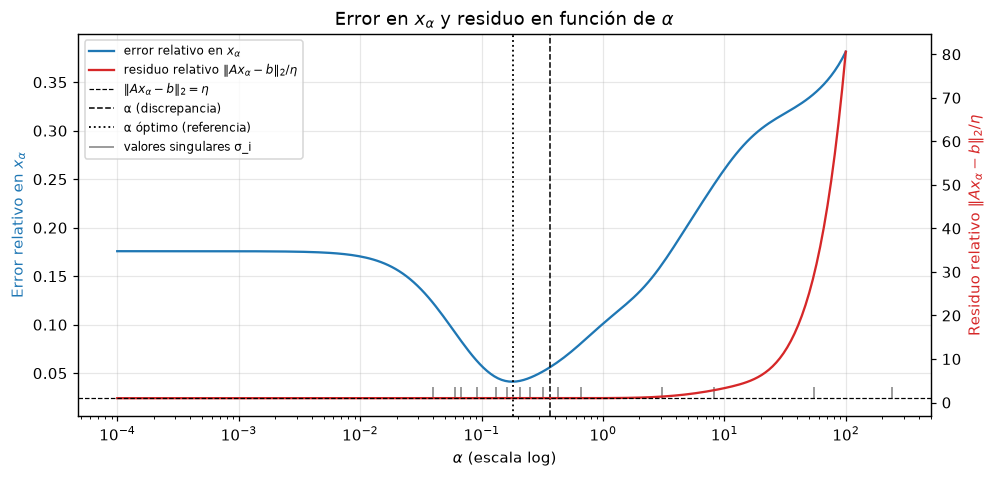

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax2 = ax.twinx()
ax.set_xscale("log")

l1, = ax.plot(alphas, err, "-", color="C0",
              label=r"error relativo en $x_\alpha$")
l2, = ax2.plot(alphas, res / eta, "-", color="C3",
               label=r"residuo relativo $\|A x_\alpha - b\|_2 / \eta$")
l3 = ax2.axhline(1, color="k", linestyle="--", linewidth=0.8,
                 label=r"$\|A x_\alpha - b\|_2 = \eta$")
l4 = ax.axvline(alpha_d, color="k", linestyle="--", linewidth=1,
                label="α (discrepancia)")
l5 = ax.axvline(alpha_opt, color="k", linestyle=":", linewidth=1.2,
                label="α óptimo (referencia)")
y0, y1 = ax.get_ylim()
l6 = ax.vlines(s, y0, y0 + 0.03 * (y1 - y0), color="gray", linewidth=1,
               label="valores singulares σ_i")

ax.set_xlabel(r"$\alpha$ (escala log)")
ax.set_ylabel(r"Error relativo en $x_\alpha$", color="C0")
ax2.set_ylabel(r"Residuo relativo $\|A x_\alpha - b\|_2 / \eta$", color="C3")
ax.grid(True, alpha=0.3)
ax.set_title(r"Error en $x_\alpha$ y residuo en función de $\alpha$")
ax.legend(handles=[l1, l2, l3, l4, l5, l6], loc="best", fontsize=8)

fig.savefig(FIG / "01_error_residuo_alpha.png")
plt.show()

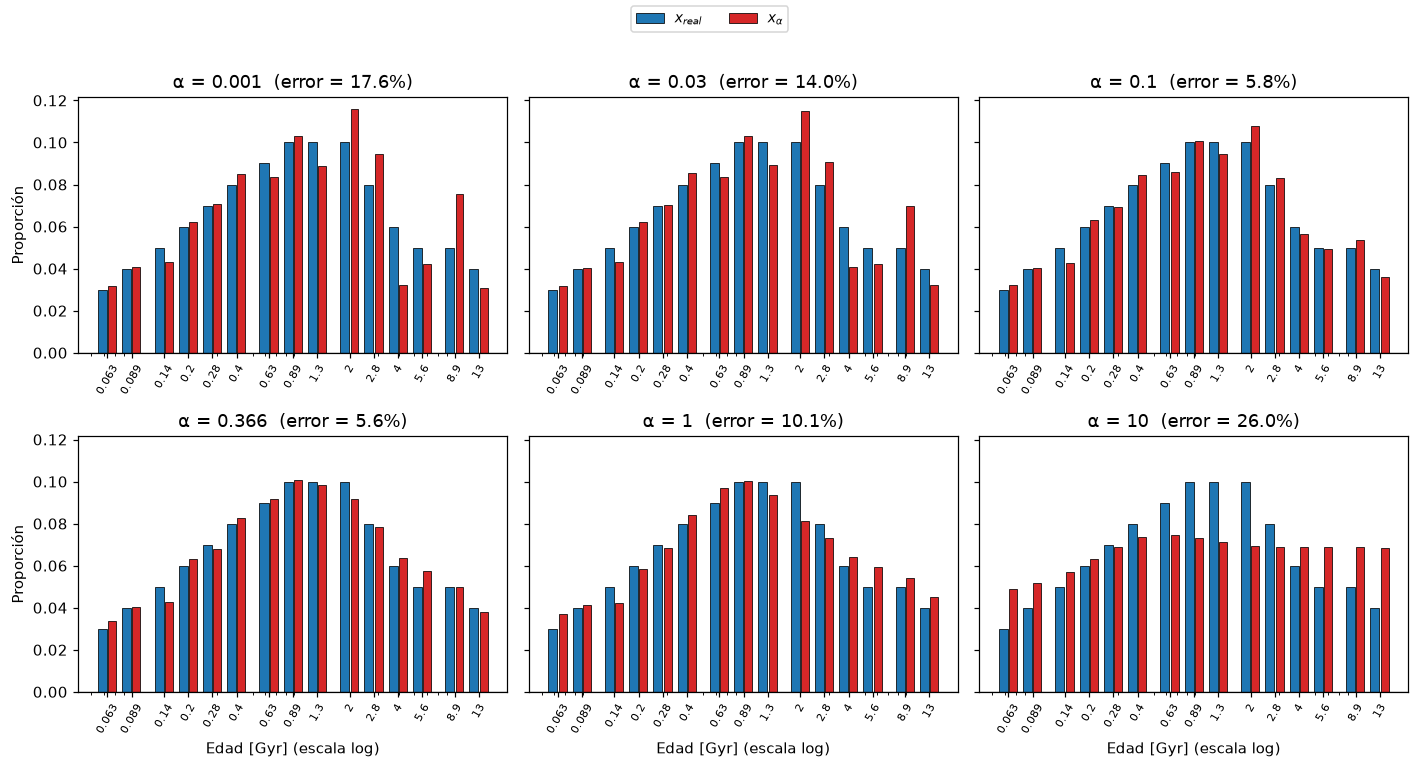

In [6]:
from matplotlib.ticker import NullFormatter

alphas_fig = [1e-3, 3e-2, 0.1, alpha_d, 1, 10]
ancho = edades * 0.12

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, a in zip(axes.ravel(), alphas_fig):
    x_a = tikhonov(a)
    err_a = err_rel(x_a)
    ax.set_xscale("log")
    ax.bar(edades * 10 ** (-0.03), x_real, width=ancho, color="C0", edgecolor="k",
           linewidth=0.5, label=r"$x_{real}$")
    ax.bar(edades * 10 ** (+0.03), x_a, width=ancho, color="C3", edgecolor="k",
           linewidth=0.5, label=r"$x_\alpha$")
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"α = {a:.3g}  (error = {err_a:.1%})")
    ax.set_xticks(edades)
    ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
    ax.xaxis.set_minor_formatter(NullFormatter())

for ax in axes[1]:
    ax.set_xlabel("Edad [Gyr] (escala log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Proporción")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))

fig.savefig(FIG / "02_xalpha_varios.png")
plt.show()

## 5. Comparación con los ítems anteriores

| Método | Error en $x$ | Residuo / $\eta$ |
|---|---|---|
| Cuadrados mínimos (Ej. 2) | 17,6 % | 0,998 |
| TSVD, $k=5$ (menor $k$ con residuo $\le\eta$, Ej. 3) | 7,2 % | 1,000 |
| TSVD, $k=11$ óptimo (referencia) | 6,5 % | 0,998 |
| **Tikhonov, $\alpha=0{,}37$ por discrepancia** | **5,6 %** | 1,000 |

- Los tres métodos **ajustan el espectro igual de bien**: el residuo es ≈ $\eta$ en todos los casos. La diferencia está solo en el espacio de los coeficientes.
- Tikhonov con $\alpha$ elegido por discrepancia da el **menor error** (5,6 %, menos de un tercio del de cuadrados mínimos) y el menor error máximo por componente (0,008 frente a 0,028). En este $b$ supera incluso a la mejor TSVD posible; con una sola realización del ruido no alcanza para afirmar que atenuar gradualmente sea mejor en general que conservar o descartar componentes enteras.
- En el gráfico de comparación, cuadrados mínimos muestra las oscilaciones en 2, 2,8, 4 y 8,9 Gyr. TSVD y Tikhonov las eliminan y siguen la forma de $x_{real}$ en todo el rango. Los errores residuales de ambos son parecidos (por ejemplo, ambos subestiman 2 Gyr y sobreestiman 4 y 5,6 Gyr): corresponden a direcciones que ningún método puede recuperar con este nivel de ruido, que es el tema del Ej. 5.

,error rel x,max|x−x_real|,residuo/η,‖x‖₂,Σx,# negativas
Cuadrados mínimos (Ej. 2),0.17577,0.0278394,0.997643,0.279204,0.999986,0
TSVD k=5 (Ej. 3),0.0720088,0.0112243,0.999895,0.272956,1.00005,0
"TSVD k=11 (óptimo, referencia)",0.0646497,0.0095791,0.99808,0.274423,1.00003,0
Tikhonov α=0.366,0.0561103,0.008247,1,0.272112,0.99999,0


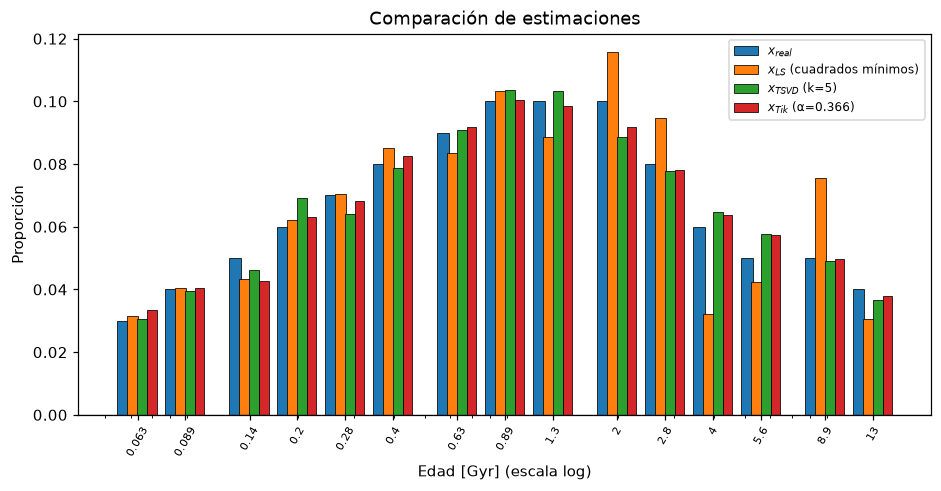

In [7]:
from matplotlib.ticker import NullFormatter

x_ls = np.linalg.lstsq(A, b, rcond=None)[0]
x_tsvd = Vt[:5].T @ (beta[:5] / s[:5])
x_tsvd_opt = Vt[:11].T @ (beta[:11] / s[:11])
x_tik = tikhonov(alpha_d)


def metricas(x):
    r = residuo(x)
    return {
        "error rel x": err_rel(x),
        "max|x−x_real|": np.max(np.abs(x - x_real)),
        "residuo/η": r / eta,
        "‖x‖₂": np.linalg.norm(x),
        "Σx": x.sum(),
        "# negativas": int(np.sum(x < 0)),
    }


comparacion = pd.DataFrame(
    [metricas(x_ls), metricas(x_tsvd), metricas(x_tsvd_opt), metricas(x_tik)],
    index=[
        "Cuadrados mínimos (Ej. 2)",
        "TSVD k=5 (Ej. 3)",
        "TSVD k=11 (óptimo, referencia)",
        f"Tikhonov α={alpha_d:.3g}",
    ],
)
display(comparacion)

series = [
    (x_real, r"$x_{real}$", "C0", 10 ** (-0.045)),
    (x_ls, r"$x_{LS}$ (cuadrados mínimos)", "C1", 10 ** (-0.015)),
    (x_tsvd, r"$x_{TSVD}$ (k=5)", "C2", 10 ** (+0.015)),
    (x_tik, f"$x_{{Tik}}$ (α={alpha_d:.3g})", "C3", 10 ** (+0.045)),
]
ancho = edades * 0.075

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.set_xscale("log")
for x, etiqueta, color, factor in series:
    ax.bar(edades * factor, x, width=ancho, color=color, edgecolor="k",
           linewidth=0.5, label=etiqueta)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_xticks(edades)
ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Edad [Gyr] (escala log)")
ax.set_ylabel("Proporción")
ax.set_title("Comparación de estimaciones")
ax.legend(fontsize=8)

fig.savefig(FIG / "03_comparacion.png")
plt.show()

## Conclusiones del ejercicio 4

1. La regularización de Tikhonov de orden 0 agrega $\alpha^2\|x\|^2$ a la función objetivo. En términos de la SVD, multiplica cada componente por $f_i=\sigma_i^2/(\sigma_i^2+\alpha^2)$, lo que atenúa las asociadas a valores singulares chicos, que son las que amplifican el ruido.
2. Resulta conveniente para este problema por lo visto en los Ej. 2 y 3: $A$ está mal condicionada y la solución sin regularizar tiene un error en $x$ ~90 veces mayor que el ruido relativo.
3. Al variar $\alpha$ aparece el compromiso entre ruido ($\alpha$ chico, $x_\alpha\to x_{LS}$) y sesgo ($\alpha$ grande, solución sobresuavizada que tiende a 0). El error es mínimo cuando $\alpha$ es del orden de los $\sigma_i$ chicos.
4. Con $\alpha\approx0{,}37$, elegido por el principio de discrepancia sin usar $x_{real}$, el error baja del 17,6 % al **5,6 %**, con el mismo residuo. Con este $b$ es el de menor error entre los métodos comparados, aunque con una sola realización del ruido no alcanza para afirmar que le gane siempre a la TSVD.